In [79]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pandas Dataframe

In [80]:
df = pd.read_csv("state_data.csv")

In [81]:
print(df.shape)

(52, 4)


In [82]:
print(df.head())
print(df.tail())

  state   latitude   longitude        name
0    AK  63.588753 -154.493062      Alaska
1    AL  32.318231  -86.902298     Alabama
2    AR  35.201050  -91.831833    Arkansas
3    AZ  34.048928 -111.093731     Arizona
4    CA  36.778261 -119.417932  California
   state   latitude   longitude           name
47    VT  44.558803  -72.577841        Vermont
48    WA  47.751074 -120.740139     Washington
49    WI  43.784440  -88.787868      Wisconsin
50    WV  38.597626  -80.454903  West Virginia
51    WY  43.075968 -107.290284        Wyoming


In [83]:
median_lat = df["latitude"].median()
median_lon = df["longitude"].median()
print(f"Median latitude: {median_lat:.2f}, median longitude: {median_lon:.2f}")

Median latitude: 39.44, median longitude: -89.09


In [84]:
df["lat_distance"] = (df["latitude"] - median_lat).abs()
df["lon_distance"] = (df["longitude"] - median_lon).abs()

In [85]:
print(df.shape)

(52, 6)


In [86]:
closest_lat = df.loc[df["lat_distance"].idxmin()]
farthest_lat = df.loc[df["lat_distance"].idxmax()]
closest_lon = df.loc[df["lon_distance"].idxmin()]
farthest_lon = df.loc[df["lon_distance"].idxmax()]

In [87]:
print(f"Closest to median latitude: {closest_lat['name']} by {closest_lat['lat_distance']:.2f}")
print(f"Farthest from median latitude: {farthest_lat['name']} by {farthest_lat['lat_distance']:.2f}")
print(f"Closest to median longitude: {closest_lon['name']} by {closest_lon['lon_distance']:.2f}")
print(f"Farthest from median longitude: {farthest_lon['name']} by {farthest_lon['lon_distance']:.2f}")

Closest to median latitude: Colorado by 0.11
Farthest from median latitude: Alaska by 24.15
Closest to median longitude: Illinois by 0.31
Farthest from median longitude: Hawaii by 66.57


In [88]:
print(df.nlargest(5, "lat_distance")[["name", "lat_distance"]])

           name  lat_distance
0        Alaska     24.153237
39  Puerto Rico     21.214683
11       Hawaii     19.536834
9       Florida     11.770689
48   Washington      8.315559


# Seaborn 

In [89]:
df = sns.load_dataset("tips")

In [90]:
df= df.dropna(axis=1)

In [91]:
print(df.shape) #(244, 7)
print(f"Rows: {df.shape[0]}, columns: {df.shape[1]}")
print(df.head())
print(df.tail())
print(df.columns.tolist())

(244, 7)
Rows: 244, columns: 7
   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
     total_bill   tip     sex smoker   day    time  size
239       29.03  5.92    Male     No   Sat  Dinner     3
240       27.18  2.00  Female    Yes   Sat  Dinner     2
241       22.67  2.00    Male    Yes   Sat  Dinner     2
242       17.82  1.75    Male     No   Sat  Dinner     2
243       18.78  3.00  Female     No  Thur  Dinner     2
['total_bill', 'tip', 'sex', 'smoker', 'day', 'time', 'size']


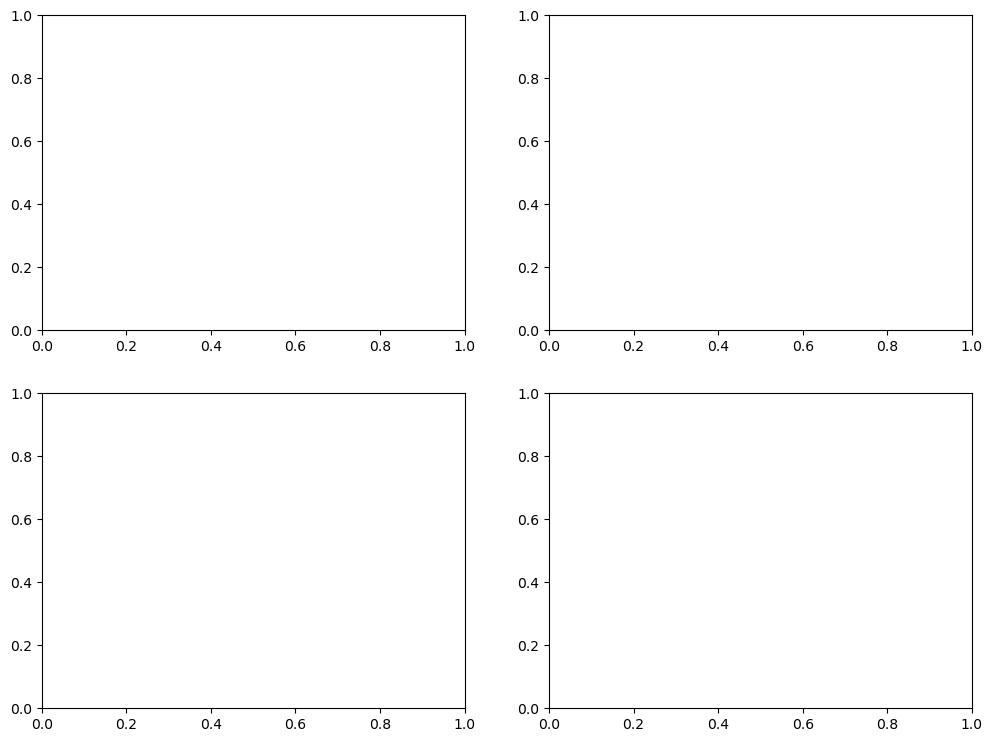

In [92]:
fig, axes = plt.subplots(2, 2, figsize=(12,9))

In [96]:
sns.scatterplot(data=df, x="total_bill", y="tip", hue="time", palette=["tab:blue", "tab:orange"], ax=axes[0, 0])
axes[0, 0].set_title("Tip vs. Total Bill")
axes[0, 0].set_xlabel("Total Bill (USD)")
axes[0, 0].set_ylabel("Tip (USD)")
axes[0, 0].legend(title="Meal time")

In [98]:
sns.scatterplot(data=df, x="size", y="tip", color="tab:green", ax=axes[0, 1])
axes[0, 1].set_title("Tip vs. Party Size")
axes[0, 1].set_xlabel("Party Size (number of people)")
axes[0, 1].set_ylabel("Tip (USD)")

Text(511.7171717171717, 0.5, 'Tip (USD)')

In [99]:
sns.histplot(data=df, x="total_bill", bins=20, color="tab:red", ax=axes[1, 0])
axes[1, 0].set_title("Distribution of Total Bill")
axes[1, 0].set_xlabel("Total Bill (USD)")
axes[1, 0].set_ylabel("Count of parties")

Text(4.444444444444452, 0.5, 'Count of parties')

In [100]:
sns.boxplot(data=df, x="day", y="total_bill", color="tab:purple", ax=axes[1, 1])
axes[1, 1].set_title("Total Bill by Day of Week")
axes[1, 1].set_xlabel("Day of week")
axes[1, 1].set_ylabel("Total Bill (USD)")

Text(511.7171717171717, 0.5, 'Total Bill (USD)')

In [101]:
plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

In [102]:
'''
Tip vs total bill, party size: because tipping is a percentage of a bill, so they should be closely related
Total bill: shows how bills are given, distribution is right skewed
Total bill by day: Spending across several days, weekends look higher than weekdays
'''

'\nTip vs total bill, party size: because tipping is a percentage of a bill, so they should be closely related\nTotal bill: shows how bills are given, distribution is right skewed\nTotal bill by day: Spending across several days, weekends look higher than weekdays\n'